# Task 3: Let each key $k$ select a diagonal phase operator $D_k$

$n = 6$ qubits, $d = 2^n = 64$, and $K = 4$ keys $k \in \{0,1,2,3\}$ (2 key bits for a 6-bit message, so the key is shorter than the message, as data locking requires).

$$D_k=\mathrm{diag}\big(e^{i\theta_{k,0}},\dots,e^{i\theta_{k,d-1}}\big),\qquad D_k|x\rangle=e^{i\theta_{k,x}}|x\rangle$$

- **Diagonal with modulus-1 entries:** $D_k$ is unitary and only changes phases, never measurement probabilities in the computational basis.
- **One independent random phase per basis state:** the angles $\theta_{k,x}$ are drawn uniformly from $[0,2\pi)$, so $\mathbb E[e^{i\theta}]=0$ as in the paper.
- **Classical key:** $k$ is a Python integer that selects which $D_k$ is appended after $F$. The circuit stays at $n$ qubits.
- **Shared codebook:** Alice and Bob regenerate the same $K\times d$ table of angles from a fixed seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit.circuit.library import QFTGate, DiagonalGate

N = 6
d = 2**N
M = d
messages = list(range(M))

K = 4
keys = list(range(K))
SEED = 2026
MODE = "uniform"

## Tasks 1–2 (reference)

In [2]:
def ket(m, d):
    return Statevector.from_int(m, d)


def encode_message(m, n):
    """Return an n-qubit circuit preparing |m> from |0...0>."""
    if not (0 <= m < 2**n):
        raise ValueError(f"m={m} does not fit in n={n} qubits")
    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)
    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])
    return qc


def dft_matrix(n):
    d = 2**n
    x = np.arange(d)
    return np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)


def encode_and_qft(m, n):
    """Return an n-qubit circuit preparing F|m> from |0...0>."""
    qc = encode_message(m, n)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    return qc


F = dft_matrix(N)

In [3]:
def plot_circles(state, title="", cols=8, size=1.1):
    """Draw a state in the course's circle notation.

    For every basis state |j>:
      * grey outline  = the maximum possible magnitude (1)
      * filled disk   = radius proportional to |amplitude|  (so area ~ probability)
      * dark line     = the phase of the amplitude: phase 0 points straight UP and
                        the line rotates COUNTER-CLOCKWISE as the phase grows.
    """
    amps = np.asarray(state.data if hasattr(state, "data") else state, dtype=complex)
    d = len(amps)
    n = int(np.log2(d))
    cols = min(cols, d)
    rows = int(np.ceil(d / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 1.15))
    axes = np.atleast_1d(axes).ravel()
    for j, ax in enumerate(axes):
        ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
        ax.set_aspect("equal"); ax.axis("off")
        if j >= d:
            continue
        r = abs(amps[j])
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6", lw=1))
        if r > 1e-9:
            ax.add_patch(plt.Circle((0, 0), r, color="#4a90d9", alpha=0.75))
            phi = np.angle(amps[j])
            ax.plot([0, -r * np.sin(phi)], [0, r * np.cos(phi)], color="#0b2545", lw=1.6)
        ax.set_title(f"|{j}>\n{j:0{n}b}", fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## The key codebook

`make_codebook` returns the $K\times d$ array of angles. A local generator seeded with `SEED` makes the codebook reproducible and independent of any other random calls. `mode="binary"` (angles in $\{0,\pi\}$, entries $\pm1$) is kept as the simpler variant; the project uses `mode="uniform"`. The codebook is saved to `codebook.npz` for Tasks 4–5.

In [4]:
def make_codebook(n, K, seed=SEED, mode=MODE):
    """K x 2^n array of phase angles; row k defines D_k."""
    d = 2**n
    rng = np.random.default_rng(seed)
    if mode == "uniform":
        return rng.uniform(0.0, 2.0 * np.pi, size=(K, d))
    if mode == "binary":
        return np.pi * rng.integers(0, 2, size=(K, d))
    raise ValueError(f"unknown mode {mode!r}")


thetas = make_codebook(N, K)
np.savez("codebook.npz", thetas=thetas, K=K, N=N, seed=SEED, mode=MODE)

assert thetas.shape == (K, d)
assert np.allclose(thetas, make_codebook(N, K))              # reproducible
print("codebook shape:", thetas.shape)
print("|mean(e^{i theta})| =", round(np.abs(np.mean(np.exp(1j * thetas))), 4),
      "   1/sqrt(K d) =", round(1 / np.sqrt(K * d), 4))

codebook shape: (4, 64)
|mean(e^{i theta})| = 0.0829    1/sqrt(K d) = 0.0625


## $D_k$ as a matrix and as a gate

`D_matrix` builds the full diagonal matrix. `D_gate` builds the Qiskit `DiagonalGate`, which takes the complex entries $e^{i\theta_{k,x}}$; entry $x$ acts on basis state $|x\rangle$ in Qiskit's little-endian numbering, so the gate matrix equals `D_matrix`. Bob undoes the key with $D_k^\dagger = D_k^{-1} = \mathrm{diag}(e^{-i\theta_{k,x}})$.

In [5]:
def D_matrix(theta_row):
    return np.diag(np.exp(1j * np.asarray(theta_row)))


def D_gate(theta_row, name="D_k"):
    # D_k as a Qiskit instruction: a DiagonalGate wrapped in a box named D_k
    n = int(np.log2(len(theta_row)))
    qc = QuantumCircuit(n, name=name)
    qc.append(DiagonalGate(list(np.exp(1j * np.asarray(theta_row)))), range(n))
    return qc.to_instruction()


I = np.eye(d)
for k in keys:
    Dk = D_matrix(thetas[k])
    assert np.allclose(Operator(D_gate(thetas[k])).data, Dk)        # gate = matrix
    assert np.allclose(Dk.conj().T @ Dk, I)                          # unitary
    assert np.allclose(Dk.conj().T, D_matrix(-thetas[k]))            # D_k^dagger
    assert np.allclose(np.abs(Dk @ F), np.abs(F))                    # magnitudes unchanged

print("✅ for every key: D_gate = D_matrix, D_k unitary, D_k^dagger = diag(e^{-i theta}), |D_k F| = |F|")

✅ for every key: D_gate = D_matrix, D_k unitary, D_k^dagger = diag(e^{-i theta}), |D_k F| = |F|


## The keys are distinct

The overlap $\left|\frac1d\sum_x e^{i(\theta_{k,x}-\theta_{k',x})}\right|$ is 1 for the same key and of order $1/\sqrt d = 0.125$ for two different random keys, so a wrong key leaves most of the random phase in place.

In [6]:
E = np.exp(1j * thetas)
overlap = np.abs(E @ E.conj().T) / d
print(np.round(overlap, 3))

[[1.    0.167 0.053 0.171]
 [0.167 1.    0.161 0.193]
 [0.053 0.161 1.    0.23 ]
 [0.171 0.193 0.23  1.   ]]


## Circle notation: the key phases and the locked state

The first plot is the diagonal of $D_k$ for $k = 2$: every entry has modulus 1 and an independent random phase. Applying it to $F|37\rangle$ keeps every circle the same size ($1/\sqrt{64}$) but replaces the regular phase rotation of $F|37\rangle$ with random phases.

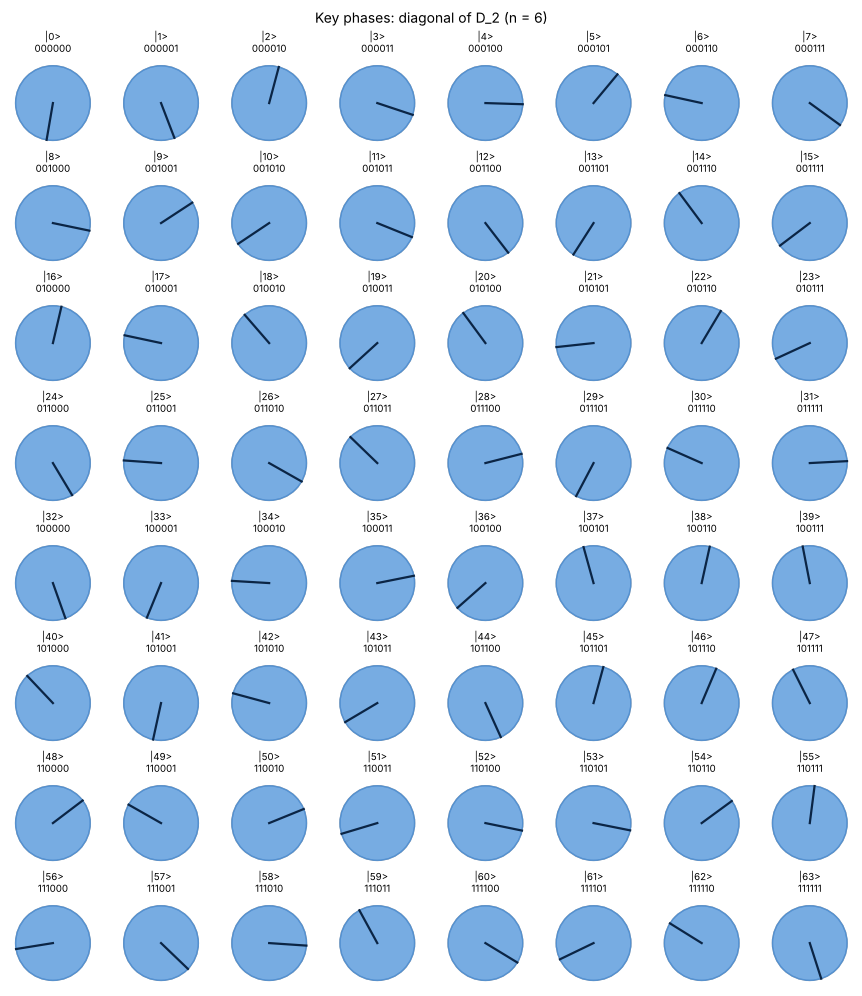

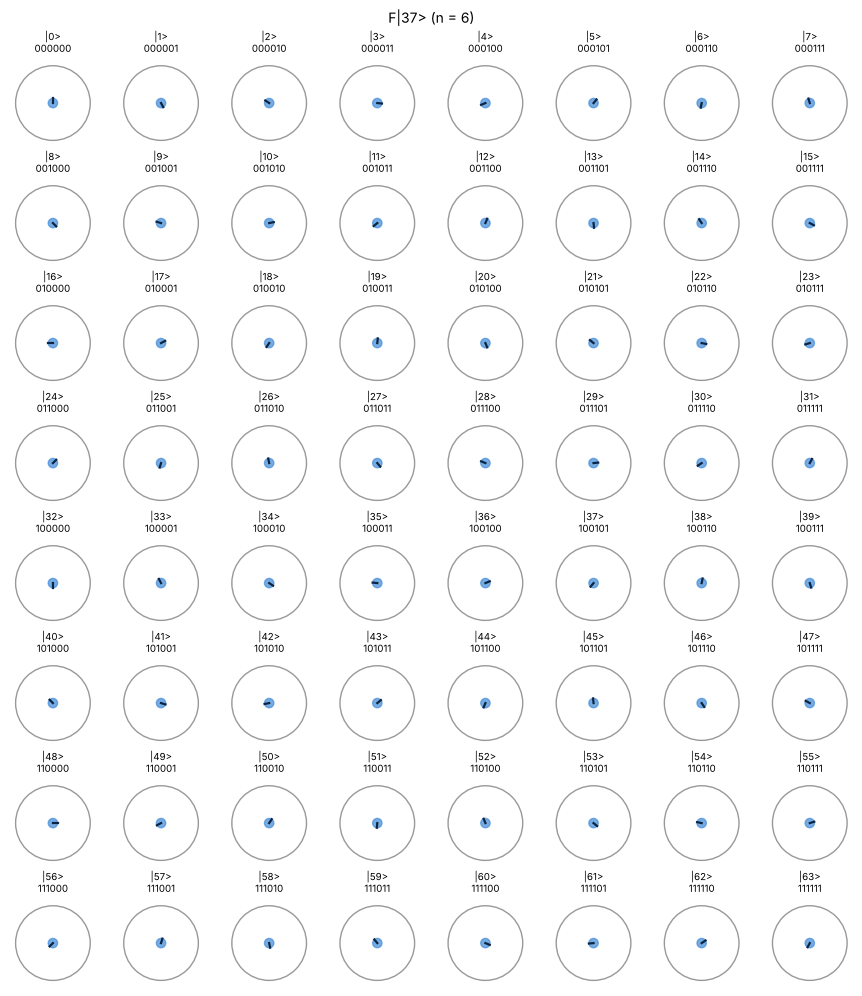

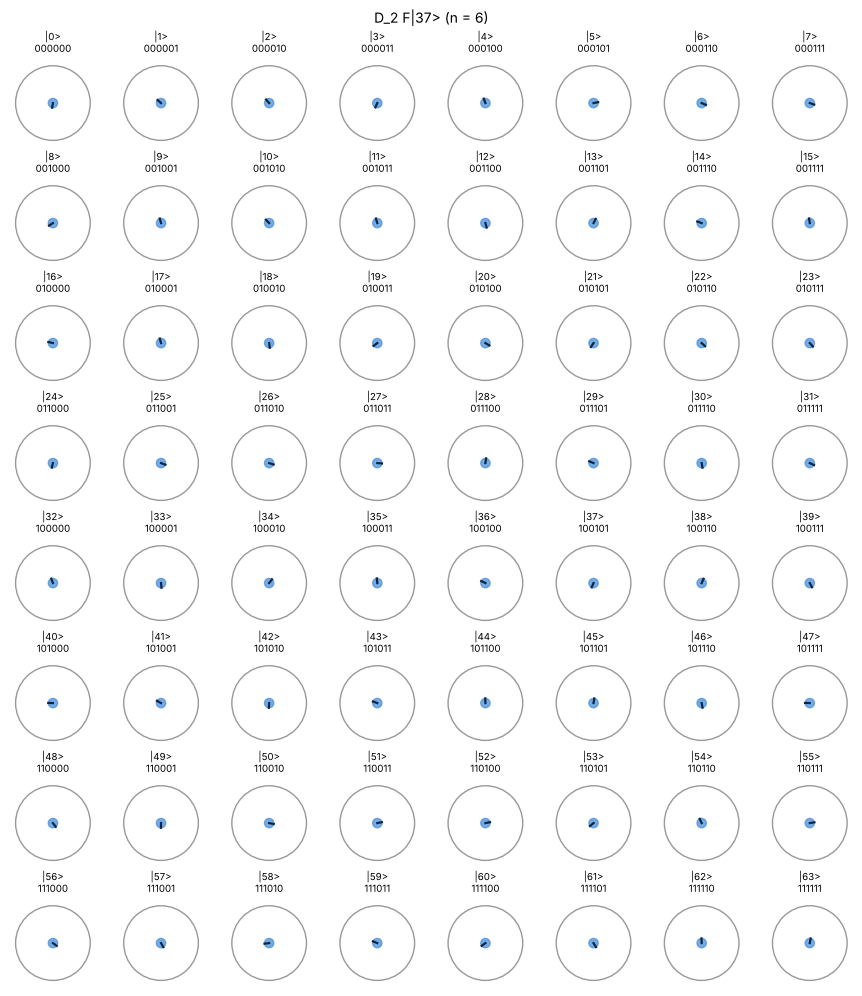

In [7]:
m, k = 37, 2
plot_circles(np.exp(1j * thetas[k]), f"Key phases: diagonal of D_{k} (n = 6)")
plot_circles(Statevector.from_instruction(encode_and_qft(m, N)), f"F|{m}> (n = 6)")
plot_circles(Statevector(D_matrix(thetas[k]) @ F[:, m]), f"D_{k} F|{m}> (n = 6)")

## Circuit: $|0\dots0\rangle \to |m\rangle \to F|m\rangle \to D_k F|m\rangle$

The key is classical: it only decides which `DiagonalGate` is appended after the QFT.

In [8]:
def encode_qft_key(m, k, n, thetas):
    """Return an n-qubit circuit preparing D_k F|m> from |0...0>."""
    qc = encode_and_qft(m, n)
    qc.barrier()
    qc.append(D_gate(thetas[k], name=f"D_{k}"), range(n))
    return qc


qc = encode_qft_key(37, 2, N, thetas)
print(qc.draw("text"))

       ┌───┐ ░ ┌──────┐ ░ ┌──────┐
msg_0: ┤ X ├─░─┤0     ├─░─┤0     ├
       └───┘ ░ │      │ ░ │      │
msg_1: ──────░─┤1     ├─░─┤1     ├
       ┌───┐ ░ │      │ ░ │      │
msg_2: ┤ X ├─░─┤2     ├─░─┤2     ├
       └───┘ ░ │  Qft │ ░ │  D_2 │
msg_3: ──────░─┤3     ├─░─┤3     ├
             ░ │      │ ░ │      │
msg_4: ──────░─┤4     ├─░─┤4     ├
       ┌───┐ ░ │      │ ░ │      │
msg_5: ┤ X ├─░─┤5     ├─░─┤5     ├
       └───┘ ░ └──────┘ ░ └──────┘


In [9]:
for k in keys:
    Dk = D_matrix(thetas[k])
    for m in messages:
        sv = Statevector.from_instruction(encode_qft_key(m, k, N, thetas))
        assert np.allclose(sv.data, Dk @ F[:, m]), f"failed for m={m}, k={k}"

print("✅ all", M, "messages x", K, "keys mapped to D_k F|m>")

✅ all 64 messages x 4 keys mapped to D_k F|m>


## Why the phases must be random

A linear phase $\theta_x = 2\pi s x/d$ is not a valid key: combining it with $F|m\rangle$ gives
$$D_{\text{lin}}F|m\rangle=\frac1{\sqrt d}\sum_x e^{2\pi i (m+s)x/d}|x\rangle = F|m+s \bmod d\rangle,$$
so it only shifts the message (a Caesar cipher), and $F^\dagger$ reads off $m+s$ directly. A constant phase $\theta_x=c$ gives $D=e^{ic}I$, a global phase with no effect at all. With a random $D_k$, $F^\dagger D_k F|m\rangle$ is spread over many basis states.

In [10]:
s = 3
theta_lin = 2 * np.pi * s * np.arange(d) / d
for m in messages:
    assert np.allclose(D_matrix(theta_lin) @ F[:, m], F[:, (m + s) % d])
print(f"✅ linear phase with s = {s}: D_lin F|m> = F|m+{s} mod {d}> for every m")

m = 37
p_lin = np.abs(F.conj().T @ D_matrix(theta_lin) @ F[:, m])**2
p_key = np.abs(F.conj().T @ D_matrix(thetas[2]) @ F[:, m])**2
print(f"F^dagger D_lin F|{m}>: outcome {p_lin.argmax()} with probability {p_lin.max():.3f}")
print(f"F^dagger D_2   F|{m}>: largest probability {p_key.max():.3f} (spread over {np.sum(p_key > 1e-3)} outcomes)")

✅ linear phase with s = 3: D_lin F|m> = F|m+3 mod 64> for every m
F^dagger D_lin F|37>: outcome 40 with probability 1.000
F^dagger D_2   F|37>: largest probability 0.060 (spread over 60 outcomes)
